In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
import time

In [3]:
import scipy.stats as ss
import scikit_posthocs as sp

In [4]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.linear_model import ElasticNet
from interpret.glassbox import ExplainableBoostingRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from fastai.tabular.all import *
from fastai.metrics import mse
from sklearn.model_selection import train_test_split

In [5]:
sns.set_theme(style="darkgrid")
sns.set_palette('tab10')

## Tuning dadaset

In [7]:
n_trial = 0 # Trial number of the LHS
n_sp = 4

In [8]:
df_projects=pd.read_csv(os.path.join('./montecarlo','model_selection_projects.csv'))
print('Project dataset for model selection:')
df_projects[df_projects['ModelSelection']].pivot_table(columns='SP', values='Project', aggfunc='count')

Project dataset for model selection:


SP,0.068966,0.172414,0.275862,0.379310,0.482759,0.586207,0.689655,0.793103,0.896552
Project,10,10,10,10,10,10,10,10,10


In [9]:
# Tuning dataser n_sp=4
sp_values=df_projects['SP'].unique() 
df_tuning=df_projects[df_projects['ModelSelection'] & (df_projects['SP']==sp_values[n_sp])] 
print(f"Dataset of {df_tuning.shape[0]} projects for model selection with SP values {sp_values[n_sp]:.6f}")
print(f"List of projects of the tuning dataset: {[ project for project in df_tuning['Project']]}")

Dataset of 10 projects for model selection with SP values 0.482759
List of projects of the tuning dataset: ['ev402', 'ev408', 'ev424', 'ev431', 'ev438', 'ev454', 'ev462', 'ev464', 'ev467', 'ev481']


## LHS hyperparameters

In [31]:
# Generate Latin Hypercube Sampling (LHS) parameters
def generate_lhs_parameters(hyperparameters, Nlhs):
    lhs_pam = {}
    for param, config in hyperparameters.items():
        scale, dtype, a, b = config[:4]
        if scale == 'lin':
            if dtype == 'int':
                if (b - a) < (Nlhs - 1):
                    values = list(range(a, b + 1))
                    repetitions = (2 + (Nlhs - len(values)) // len(values))
                    lhs_pam[param] = (values * repetitions)[:Nlhs]
                else:
                    lhs_pam[param] = np.linspace(a, b, Nlhs).astype(int)
            elif dtype == 'float':
                lhs_pam[param] = np.linspace(a, b, Nlhs)
        elif scale == 'log':
            lhs_pam[param] = np.geomspace(10**a, 10**b, Nlhs)
        else:
            print(f"Unknown scale type '{scale}' for parameter '{param}'")
    return lhs_pam

In [32]:
def generate_lhs_parameters_file(hyperparameters, Nlhs=20,Ntrials=1):
    for t in range(Ntrials):
        for model in hyperparameters.keys():
            #  Generate Latin Hypercube Sampling (LHS) parameters
            df_pam=pd.DataFrame(generate_lhs_parameters(hyperparameters[model],Nlhs))
            df_pam.index.name = 'lhs'
            # Random permutation of the columns
            df_pam=df_pam.apply(lambda column: np.random.permutation(column), axis=0)
            # Save the parameters to a CSV file
            df_pam.to_csv(f"tuning/lhs{t}_{model}_parameters.csv",index=True)

## Training and testing

In [10]:
# Training with default hyperparameters
def train_sample(df_project, mdl_name, hiperparam=None):

    # Load the model
    if mdl_name == 'rf':
        mdl = RandomForestRegressor
    elif mdl_name == 'xgb':
        mdl = XGBRegressor
    elif mdl_name == 'ebm':
        mdl = ExplainableBoostingRegressor
    elif mdl_name == 'sv':
        mdl = SVR
    elif mdl_name == 'en':
        mdl = ElasticNet
    else:
        return None

    mse_test = []
    for project in df_project['Project']:
        # Read the simulation data
        df = pd.read_csv(os.path.join('./montecarlo',f"{project}_simulation_e1.csv"),index_col=0)
        # Read test runs
        df_runs= pd.read_csv(os.path.join('./montecarlo',"test_runs.csv"))

        # Training data
        df_train=df.loc[df.index.difference(df_runs['test_runs'].values)]
        Xtrain=df_train.iloc[:,:32] # 32 features correspondint to the 32 activities of the project
        Ytrain=df_train.iloc[:,-1] # Last column is the objective function: the actual duration of the project 
        # Testing data
        df_test=df.loc[df_runs['test_runs'].values]
        Xtest=df_test.iloc[:,:32]
        Ytest=df_test.iloc[:,-1]

        # Load the model
        if hiperparam is not None:
            model=mdl(**hiperparam)
        else:
            model=mdl()

        # Fit the model with scaled data for all features
        scaler = StandardScaler()   
        Xtrain_scaled = scaler.fit_transform(Xtrain)
        Xtest_scaled = scaler.transform(Xtest)
        model.fit(Xtrain_scaled,Ytrain)
        Ypred=model.predict(Xtest_scaled)      
        # Calculate the MSE
        mse = mean_squared_error(Ytest, Ypred)
        # Update the test run
        mse_test.append([project,mse])
    return mse_test


In [11]:
def training(df_project, df_param, mdl_name, n_sp, n_trial, seed=42):

    # Load the model
    if mdl_name == 'rf':
        mdl = RandomForestRegressor
    elif mdl_name == 'xgb':
        mdl = XGBRegressor
    elif mdl_name == 'ebm':
        mdl = ExplainableBoostingRegressor
    elif mdl_name == 'sv':
        mdl = SVR
    elif mdl_name == 'en':
        mdl = ElasticNet
    else:
        return None

    # Test the combinations of hyperparameters over a subset of projects SPj
    mse_test = []
    for project in df_project['Project']:

        # Read the simulation data
        df = pd.read_csv(os.path.join('./montecarlo',f"{project}_simulation_e1.csv"),index_col=0)

        # Read test runs
        df_runs= pd.read_csv(os.path.join('./montecarlo',"test_runs.csv"))

        # Training data
        df_train=df.loc[df.index.difference(df_runs['test_runs'].values)]
        Xtrain=df_train.iloc[:,:32] # 32 features correspondint to the 32 activities of the project
        Ytrain=df_train.iloc[:,-1] # Last column is the objective function: the actual duration of the project
        
        # Testing data
        df_test=df.loc[df_runs['test_runs'].values]
        Xtest=df_test.iloc[:,:32]
        Ytest=df_test.iloc[:,-1]

        # Test all combinations of hiperparameters
        for i in df_param.index:

            print(f"Running {mdl_name} for {project} with {i}-LHShyperparameters")
            # For comuting the run time
            start_time = time.time()

            # Load the model
            hyperparameters = df_param.iloc[[i]].to_dict(orient='records')[0] # Using `.loc[i, :]` returns a Series, which may upcast ints to floats — use `.iloc[[i]]` for dtype-safe row extraction.
            if mdl_name in ['rf','xgb','ebm']:
                hyperparameters['random_state'] = seed
                hyperparameters['n_jobs'] = -1
            elif mdl_name in ['en']:
                hyperparameters['random_state'] = seed
            # SV is a deterministic model, so no need to set the random state

            if mdl_name == 'xgb':
                hyperparameters['learning_rate'] = 1/np.sqrt(hyperparameters['n_estimators'])
            
            model=mdl(**hyperparameters)

            # Fit the model with scaled data for all features
            scaler = StandardScaler()   
            Xtrain_scaled = scaler.fit_transform(Xtrain)
            Xtest_scaled = scaler.transform(Xtest)
            model.fit(Xtrain_scaled,Ytrain)
            Ypred=model.predict(Xtest_scaled)
            
            # Calculate the MSE
            mse = mean_squared_error(Ytest, Ypred)

            end_time = time.time()
            elapsed_time = round(end_time - start_time,0) # in seconds

            # Update the test run
            mse_test.append([sp_values[n_sp],project,i] + [df_param.loc[i,c] for c in df_param.columns] + [mse,elapsed_time])

    # Save the results of the model selection
    pd.DataFrame(mse_test,columns=['SP','Project','lhs'] + df_param.columns.tolist() + ['MSE','time']).to_csv(f"./tuning/lhs{n_trial}_model_tuning_{mdl_name}_{n_sp}.csv",index=False)


In [45]:
def fastai_training(df_project, df_param, mdl_name, n_sp, n_trial, seed=42):

    # Test the combinations of hyperparameters over a subset of projects SPj
    mse_test = []
    for project in df_project['Project']:

        # Read the simulation data
        df = pd.read_csv(os.path.join('./montecarlo',f"{project}_simulation_e1.csv"),index_col=0)

        # Read test runs
        df_runs= pd.read_csv(os.path.join('./montecarlo',"test_runs.csv"))

        # Training and testing data
        df_train=df.loc[df.index.difference(df_runs['test_runs'].values)]
        df_test=df.loc[df_runs['test_runs'].values]

        # (1) Prepare training/validation set
        splits = RandomSplitter(valid_pct=0.1)(range_of(df_train)) # We assign the validation set to 10% of the training data
        to = TabularPandas(df_train, 
                procs=[Categorify,FillMissing,Normalize],
                cat_names = [],
                cont_names = [ col for col in df_train.columns if col.startswith('duration')],
                y_names='actual_duration',
                splits=splits)
        # Create DataLoaders, 'dls' will have 'train' and 'valid' DataLoaders
        dls = to.dataloaders(bs=64) # Try other batch sizes?

        # Test all combinations of hiperparameters
        for i in df_param.index:

            print(f"Running {mdl_name} for {project} with {i}-LHShyperparameters")
            # For comuting the run time
            start_time = time.time()

            # Load layers

            layers=[]
            for c in df_param.columns:
                if c == 'layer1':
                    layers.append(int((df_param.loc[i,c]//5)*5)) # Round to the nearest multiple of 5
                elif c == 'layer2':
                    layers.append(int((df_param.loc[i,c]//5)*5)) # Round to the nearest multiple of 5
                elif c == 'wd':
                    wd = float(df_param.loc[i,c])
                elif c == 'ps':
                    ps = float(df_param.loc[i,c])

            # (2) Train the model
            epochs = 100
            learn = tabular_learner(
                dls,
                layers=layers,
                metrics=mse,
                config=tabular_config(ps=ps), # Dropout for embedding layers
                wd=wd, # Weight decay
                loss_func=MSELossFlat(), # Mean Squared Error as regression loss
                cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=10)]
            )
            # Find the best learning rate
            lr_suggestion = learn.lr_find(show_plot=False)
            # and train the model
            learn.fit_one_cycle(epochs, lr_max=lr_suggestion)

            # (3) Evaluate the model on the test dataset
            test_dl = learn.dls.test_dl(df_test)
            test_preds = learn.get_preds(dl=test_dl)
            test_mse = mse(test_preds[0], tensor(df_test['actual_duration'].values)).item()
            test_mse

            end_time = time.time()
            elapsed_time = round(end_time - start_time,0) # in seconds

            # Update the test run
            mse_test.append([sp_values[n_sp],project,i] + layers + [wd,ps] + [test_mse,elapsed_time])

    # Save the results of the model selection



## Statistics for model evaluation

In [25]:
# Statistical comparison of models' performance
def model_comparison(data, significance=0.05):

  # Rank the models (percentage rank)
  rank=data.rank(axis=1,pct=True)
  avg_rank=rank.mean()

  # Friedman test
  friedman_test=ss.friedmanchisquare(*data.values.T)
  print(f"Friedman's test p-value: {friedman_test.pvalue}")
  
  # Critical difference diagram incase of rejection of null hypothesis
  if friedman_test.pvalue < significance:
    print("Reject null hypothesis that all models are equally good")
    print("Conover's test for all pairs of models...\n")
    conover_test=sp.posthoc_conover_friedman(data, p_adjust='bonferroni')
    plt.figure(figsize=(10, 2))
    plt.title("Critical difference diagram of normalized score ranks")
    sp.critical_difference_diagram(avg_rank, conover_test);

## XGboost

In [12]:
mdl_name='xgb'

### Default parameterization

In [14]:
train_sample(df_tuning.iloc[:2,:],mdl_name='xgb', hiperparam=None)

[['ev402', 0.2864510961249591], ['ev408', 0.3694016248094031]]

In [15]:
train_sample(df_tuning.iloc[:2,:],mdl_name='xgb', hiperparam={
    'n_estimators': 1000,
    'max_depth': 3,
    'learning_rate': 1/np.sqrt(1000),
    'reg_alpha': 0.5,
    'reg_lambda': 1,
    'random_state': 42
})

[['ev402', 0.064601237640643], ['ev408', 0.09809158199492952]]

### LHS parameter exploring

In [33]:
# Hyperparameters range for exploration
# XGBoost hyperparameters
hyperparameters = {}
hyperparameters['xgb'] = {'n_estimators':('lin','int',100,2000), # Increase the maximum to 2000 afeter testing over a sample of projects
                   'max_depth':('lin','int',3,10),
                   'min_child_weight':('lin','float',1,10),
                   'reg_alpha':('lin','float',0,2),
                    'reg_lambda':('lin','float',0,2),
                   'subsample':('lin','float',0.5,1.0),
                   'colsample_bytree':('lin','float',0.3,1.0),
                   'gamma':('lin','float',0,5)}

In [34]:
hyperparameters

{'xgb': {'n_estimators': ('lin', 'int', 100, 2000),
  'max_depth': ('lin', 'int', 3, 10),
  'min_child_weight': ('lin', 'float', 1, 10),
  'reg_alpha': ('lin', 'float', 0, 2),
  'reg_lambda': ('lin', 'float', 0, 2),
  'subsample': ('lin', 'float', 0.5, 1.0),
  'colsample_bytree': ('lin', 'float', 0.3, 1.0),
  'gamma': ('lin', 'float', 0, 5)}}

In [35]:
generate_lhs_parameters_file(hyperparameters, Nlhs=20,Ntrials=1)

In [37]:
# Hyperparameters 
if os.path.exists(os.path.join('./tuning',f"lhs{n_trial}_{mdl_name}_parameters.csv")):
    df_param=pd.read_csv(os.path.join('./tuning',f"lhs{n_trial}_{mdl_name}_parameters.csv"),index_col=0)
print(f"Hyperparamters of {mdl_name}: {df_param.columns.tolist()}")

Hyperparamters of xgb: ['n_estimators', 'max_depth', 'min_child_weight', 'reg_alpha', 'reg_lambda', 'subsample', 'colsample_bytree', 'gamma']


In [38]:
df_tuning.iloc[:2,:]

,Project,SP,ModelSelection
335,ev402,0.482759,True
341,ev408,0.482759,True


In [39]:
# Training/testing over the tuning dataset ...
training(df_project=df_tuning.iloc[:2,:],
         df_param=df_param, mdl_name='xgb', n_sp=4, n_trial=0, seed=42)

Running xgb for ev402 with 0-LHShyperparameters
Running xgb for ev402 with 1-LHShyperparameters
Running xgb for ev402 with 2-LHShyperparameters
Running xgb for ev402 with 3-LHShyperparameters
Running xgb for ev402 with 4-LHShyperparameters
Running xgb for ev402 with 5-LHShyperparameters
Running xgb for ev402 with 6-LHShyperparameters
Running xgb for ev402 with 7-LHShyperparameters
Running xgb for ev402 with 8-LHShyperparameters
Running xgb for ev402 with 9-LHShyperparameters
Running xgb for ev402 with 10-LHShyperparameters
Running xgb for ev402 with 11-LHShyperparameters
Running xgb for ev402 with 12-LHShyperparameters
Running xgb for ev402 with 13-LHShyperparameters
Running xgb for ev402 with 14-LHShyperparameters
Running xgb for ev402 with 15-LHShyperparameters
Running xgb for ev402 with 16-LHShyperparameters
Running xgb for ev402 with 17-LHShyperparameters
Running xgb for ev402 with 18-LHShyperparameters
Running xgb for ev402 with 19-LHShyperparameters
Running xgb for ev408 with 0-L

In [40]:
file = f"lhs{n_trial}_model_tuning_{mdl_name}_{n_sp}.csv"
if os.path.exists(os.path.join('tuning',file)):
    df = pd.read_csv(os.path.join('tuning',file))
    df['Model']=mdl_name
else:
    print(f"File {file} not found.")

Friedman's test p-value: 0.006838177694255718
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



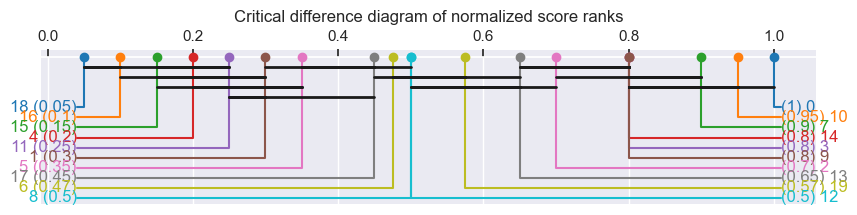

In [41]:
data= (df[['Project','lhs','MSE']].
       pivot(index='Project',columns='lhs',values='MSE'))
model_comparison(data)


In [42]:
top_5_models = df.groupby(['lhs'])['MSE'].mean().sort_values(ascending=True)[:5].index.tolist()
df.groupby(['lhs'])['MSE'].mean()[top_5_models]

lhs
18    0.080865
16    0.098850
15    0.102038
4     0.106677
11    0.121307
Name: MSE, dtype: float64

In [43]:
df_param.iloc[top_5_models]

,n_estimators,max_depth,min_child_weight,reg_alpha,reg_lambda,subsample,colsample_bytree,gamma
lhs,,,,,,,,
18,800,3,1.473684,0.526316,1.894737,0.736842,0.668421,2.368421
16,700,4,1.000000,0.000000,2.000000,0.684211,0.521053,3.157895
15,1500,5,5.736842,1.368421,0.947368,0.605263,0.705263,1.315789
4,600,5,6.210526,1.263158,0.736842,0.894737,0.373684,1.842105
11,1800,5,4.789474,2.000000,0.210526,0.973684,0.410526,2.631579


In [359]:
top_5_models = df.groupby(['lhs'])['MSE'].mean().sort_values(ascending=True)[:5].index.tolist()
df.groupby(['lhs'])['MSE'].mean()[top_5_models]

lhs
16    0.051695
0     0.076289
2     0.083854
3     0.089056
12    0.110308
Name: MSE, dtype: float64

In [319]:
df_param.iloc[top_5_models]

,n_estimators,max_depth,min_child_weight,subsample,colsample_bytree,gamma
lhs,,,,,,
16,2000,3,2.894737,0.789474,0.631579,0.526316
0,1400,3,6.210526,0.684211,0.778947,2.631579
2,600,4,3.842105,0.947368,0.557895,0.263158
3,1500,3,2.421053,0.842105,0.705263,3.421053
12,1000,5,7.157895,0.631579,0.963158,1.052632


In [362]:
df[df['Project']=='ev402'][['lhs','MSE']]

,lhs,MSE
0,0,0.064816
1,1,0.240473
2,2,0.066087
3,3,0.077087
4,4,0.104405
5,5,0.100601
6,6,0.116278
7,7,0.092057
8,8,0.232488
9,9,0.102701


## Random Forest

In [324]:
mdl_name='rf'

In [325]:
# Default hyperparameters
train_sample(df_tuning.iloc[:2,:],mdl_name='rf', hiperparam=None)

[['ev402', 0.6995635324177719], ['ev408', 1.0340662993305054]]

In [ ]:
# Random Forest hyperparameters
hyperparameters['rf'] = {'n_estimators':('lin','int',100,1000), 
                   'max_depth':('lin','int',10,30), 
                   'min_samples_split':('lin','int',2,10),
                   'min_samples_leaf':('lin','int',1,10), 
                   'max_features':('lin','float',0.3,0.9)}

In [ ]:
generate_lhs_parameters_file(hyperparameters, Nlhs=20,Ntrials=1)

In [340]:
# Hyperparameters 
if os.path.exists(os.path.join('./tuning',f"lhs{n_trial}_{mdl_name}_parameters.csv")):
    df_param=pd.read_csv(os.path.join('./tuning',f"lhs{n_trial}_{mdl_name}_parameters.csv"),index_col=0)
print(f"Hyperparamters of {mdl_name}: {df_param.columns.tolist()}")

Hyperparamters of rf: ['n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features']


In [ ]:
# Training/testing over the tuning dataset ...
training(df_project=df_tuning.iloc[:2,:],
         df_param=df_param, mdl_name='rf', n_sp=4, n_trial=0, seed=42)

Running rf for ev402 with 0-LHShyperparameters
Running rf for ev402 with 1-LHShyperparameters
Running rf for ev402 with 2-LHShyperparameters
Running rf for ev402 with 3-LHShyperparameters
Running rf for ev402 with 4-LHShyperparameters
Running rf for ev402 with 5-LHShyperparameters
Running rf for ev402 with 6-LHShyperparameters
Running rf for ev402 with 7-LHShyperparameters
Running rf for ev402 with 8-LHShyperparameters
Running rf for ev402 with 9-LHShyperparameters
Running rf for ev402 with 10-LHShyperparameters
Running rf for ev402 with 11-LHShyperparameters
Running rf for ev402 with 12-LHShyperparameters
Running rf for ev402 with 13-LHShyperparameters
Running rf for ev402 with 14-LHShyperparameters
Running rf for ev402 with 15-LHShyperparameters
Running rf for ev402 with 16-LHShyperparameters
Running rf for ev402 with 17-LHShyperparameters
Running rf for ev402 with 18-LHShyperparameters
Running rf for ev402 with 19-LHShyperparameters
Running rf for ev408 with 0-LHShyperparameters
Run

In [342]:
file = f"lhs{n_trial}_model_tuning_{mdl_name}_{n_sp}.csv"
if os.path.exists(os.path.join('tuning',file)):
    df = pd.read_csv(os.path.join('tuning',file))
    df['Model']=mdl_name
else:
    print(f"File {file} not found.")

Friedman's test p-value: 0.006451505774854242
Reject null hypothesis that all models are equally good
Conover's test for all pairs of models...



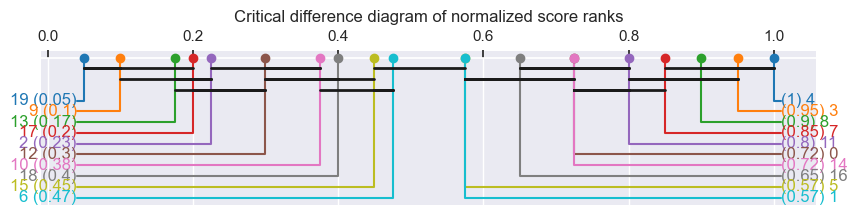

In [343]:
data= (df[['Project','lhs','MSE']].
       pivot(index='Project',columns='lhs',values='MSE'))
model_comparison(data)

In [344]:
top_5_models = df.groupby(['lhs'])['MSE'].mean().sort_values(ascending=True)[:5].index.tolist()
df.groupby(['lhs'])['MSE'].mean()[top_5_models]

lhs
19    0.841165
9     0.853057
13    0.857357
17    0.858736
2     0.864279
Name: MSE, dtype: float64

In [345]:
df_param.iloc[top_5_models]

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features
lhs,,,,,
19,573,27,3,1,0.805263
9,526,26,7,3,0.868421
13,905,18,9,2,0.836842
17,242,15,8,3,0.647368
2,478,30,4,4,0.457895


## FastAI Tabular

In [47]:
from fastai.tabular.all import *
from fastai.metrics import mse
from sklearn.model_selection import train_test_split

In [50]:
mdl_name='fastai'
hyperparameters=dict()

In [51]:
# Hyperparameters of Neural Network
hyperparameters['fastai']={
    'layer1': ('lin','int',100,500), # Number of neurons in the first layer
    'layer2': ('lin','int',50,250), # Number of neurons in the second layer
    'wd': ('log','float',-4,-2), # Weight decay
#    'ps': ('lin','float',0.25,0.75), # Dropout rates applied to each layer
}

In [426]:
generate_lhs_parameters_file(hyperparameters, Nlhs=20,Ntrials=1)

In [52]:
# Hyperparameters 
if os.path.exists(os.path.join('./tuning',f"lhs{n_trial}_{mdl_name}_parameters.csv")):
    df_param=pd.read_csv(os.path.join('./tuning',f"lhs{n_trial}_{mdl_name}_parameters.csv"),index_col=0)
print(f"Hyperparamters of {mdl_name}: {df_param.columns.tolist()}")

Hyperparamters of fastai: ['layer1', 'layer2', 'wd', 'ps']


In [ ]:
# Training/testing over the tuning dataset ...
fastai_training(df_project=df_tuning.iloc[:2,:],
         df_param=df_param, mdl_name='fastai', n_sp=4, n_trial=0, seed=42)

In [430]:
file = f"lhs{n_trial}_model_tuning_{mdl_name}_{n_sp}.csv"
if os.path.exists(os.path.join('tuning',file)):
    df = pd.read_csv(os.path.join('tuning',file))
    df['Model']=mdl_name
else:
    print(f"File {file} not found.")

In [431]:
data= (df[['Project','lhs','MSE']].
       pivot(index='Project',columns='lhs',values='MSE'))
model_comparison(data)

Friedman's test p-value: 0.7405755707525821


In [432]:
top_5_models = df.groupby(['lhs'])['MSE'].mean().sort_values(ascending=True)[:5].index.tolist()
df.groupby(['lhs'])['MSE'].mean()[top_5_models]

lhs
16    0.858126
2     0.977141
12    1.190641
19    1.216004
7     1.415694
Name: MSE, dtype: float64

In [418]:
df_param.iloc[top_5_models]

,layer1,layer2,wd
lhs,,,
19,121,250,0.002336
15,289,165,0.004833
5,373,50,0.000127
16,478,134,0.000695
14,100,228,0.010000


In [419]:
df[df['Project']=='ev402'][['lhs','MSE']]

,lhs,MSE
0,0,0.927971
1,1,0.586677
2,2,1.818175
3,3,0.101478
4,4,1.240463
5,5,0.080036
6,6,0.851915
7,7,0.198211
8,8,0.280105
9,9,0.495196


In [ ]:
# One sample ...
# Read the simulation data
df = pd.read_csv(os.path.join('./montecarlo',f"ev402_simulation_e1.csv"),index_col=0)
# Read test runs
df_runs= pd.read_csv(os.path.join('./montecarlo',"test_runs.csv"))
# Training and testing data
df_train=df.loc[df.index.difference(df_runs['test_runs'].values)]
df_test=df.loc[df_runs['test_runs'].values]

# (1) Prepare training/validation set
splits = RandomSplitter(valid_pct=0.1)(range_of(df_train)) # We assign the validation set to 10% of the training data
to = TabularPandas(df_train, 
        procs=[Categorify,FillMissing,Normalize],
        cat_names = [],
        cont_names = [ col for col in df_train.columns if col.startswith('duration')],
        y_names='actual_duration',
        splits=splits)
# Create DataLoaders, 'dls' will have 'train' and 'valid' DataLoaders
dls = to.dataloaders(bs=64) # Try other batch sizes?

# (2) Train the model
epochs = 100
learn = tabular_learner(
    dls,
    layers=[300,50],
    #config=tabular_config (ps=0.5), # Dropout
    metrics=mse,
    wd=0.0002,
    loss_func=MSELossFlat(), # Mean Squared Error as regression loss
    cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=10)]
)
# Find the best learning rate
lr_suggestion = learn.lr_find(show_plot=False)
# and train the model
learn.fit_one_cycle(epochs, lr_max=lr_suggestion)

# (3) Evaluate the model on the test dataset
test_dl = learn.dls.test_dl(df_test)
test_preds = learn.get_preds(dl=test_dl)
test_mse = mse(test_preds[0], tensor(df_test['actual_duration'].values)).item()
test_mse

epoch,train_loss,valid_loss,mse,time
0,9138.561523,8607.249023,8607.249023,00:01
1,6418.464844,4486.363281,4486.363281,00:01
2,1984.244263,256.527252,256.527252,00:01
3,432.515472,10.875536,10.875536,00:01
4,235.205353,5.588955,5.588955,00:01
5,197.796738,5.590232,5.590232,00:01
6,188.650436,17.069387,17.069387,00:01
7,189.790619,1.837677,1.837677,00:01
8,178.244690,3.752019,3.752019,00:01
9,179.112274,4.695235,4.695235,00:01


No improvement since epoch 57: early stopping


0.718214213848114